# Chapter 3 — Star Formation Statistics: Figures

**Story:** Star formation morphology, as traced by the spatial distribution of Hα
emission (via the Gini, Concentration, Asymmetry, and Smoothness/Clumpiness
diagnostics), carries information beyond global SFR and stellar mass alone.
Individually, G/C/A/S show partial, non-redundant relationships with global and
environmental properties — but no single parameter fully explains the diversity
of SF morphology, including with respect to environment. This motivates the
multivariate/ML approach taken in Chapter 4.

This notebook builds the figures in narrative order. Each figure has a short
markdown preamble stating what question it answers and why it's here, followed
by the code and the rendered output.

**Note:** Figure 5 (Concentration vs. stellar mass in halo-mass bins, following
Wang 2022 Fig. 7) is deferred pending confirmation from my supervisor on whether
a cluster-mass proxy exists for the SAMI cluster subsample.

## Setup

Load the merged catalogue, define the purity-passed sample (`in_full_sam`), and
set up shared plotting style/helpers used across all figures below.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import stats

plt.rcParams.update({
    'font.size': 13,
    'axes.labelsize': 15,
    'axes.titlesize': 15,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 11,
    'figure.dpi': 120,
    'axes.grid': False,
    'axes.linewidth': 1.3,
    'xtick.major.width': 1.2,
    'ytick.major.width': 1.2,
})

df = pd.read_csv('../outputs/csv/master_final.csv')
purity = df[df['in_full_sam'] == True].copy()
print(f'Purity-passed sample: N = {len(purity)}')

GCAS = ['G', 'C', 'A', 'S']
GCAS_LABELS = {'G': 'Gini (G)', 'C': 'Concentration (C)',
               'A': 'Asymmetry (A)', 'S': 'Smoothness/Clumpiness (S)'}
GCAS_COLOR = {'G': '#7B3294', 'C': '#0868AC', 'A': '#D7301F', 'S': '#238B45'}

def spearman_annotate(ax, x, y, loc='upper right'):
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 3:
        return
    rho, p = stats.spearmanr(x[mask], y[mask])
    text = f'$\\rho$ = {rho:.2f}\nN = {mask.sum()}'
    xy = (0.96, 0.94) if 'right' in loc else (0.04, 0.94)
    ha = 'right' if 'right' in loc else 'left'
    ax.annotate(text, xy=xy, xycoords='axes fraction', ha=ha, va='top',
                fontsize=10, bbox=dict(boxstyle='round', fc='white', ec='0.7', alpha=0.9))

def panel_label(ax, letter):
    ax.annotate(f'({letter})', xy=(0.04, 0.94), xycoords='axes fraction',
                ha='left', va='top', fontsize=13, fontweight='bold')

def binned_median_errorbar(ax, x, y, bins=8, color='black', **kwargs):
    """Bold binned-median markers with standard-error error bars, replacing
    a thin running-median line. Sparse bins (N<5) are suppressed."""
    mask = np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]
    if len(x) < bins * 3:
        return
    edges = np.linspace(np.nanmin(x), np.nanmax(x), bins + 1)
    med, _, _ = stats.binned_statistic(x, y, 'median', bins=edges)
    std, _, _ = stats.binned_statistic(x, y, 'std', bins=edges)
    cnt, _, _ = stats.binned_statistic(x, y, 'count', bins=edges)
    sem = std / np.sqrt(np.maximum(cnt, 1))
    med[cnt < 5] = np.nan
    centers = 0.5 * (edges[:-1] + edges[1:])
    ax.errorbar(centers, med, yerr=sem, fmt='o', color=color, ecolor=color,
                markersize=7, markeredgecolor='white', markeredgewidth=0.8,
                elinewidth=1.6, capsize=3, zorder=5, **kwargs)


Purity-passed sample: N = 837


## Figure 1 — Characterising the Sample (SFMS)

**Question this answers:** where does the sample sit relative to
the star-forming main sequence (SFMS)? The aim here is to set the scene cleanly before
any GCAS result is introduced.

**Don't use this one, instead use the one produced in sfms_explorer.ipynb**


## Figure 2 — GCAS vs. global properties

**Question this answers:** how does each GCAS parameter individually relate to
stellar mass, sSFR, and SFR? One row per parameter (G, C, A, S), one column per
global property (Mstar, sSFR, SFR) — 4×3 grid, shared style, Spearman ρ
annotated in each panel. Each parameter uses its own valid-N mask (`in_G`,
`in_C`, `in_A`, `in_S`), since coverage differs slightly between them.

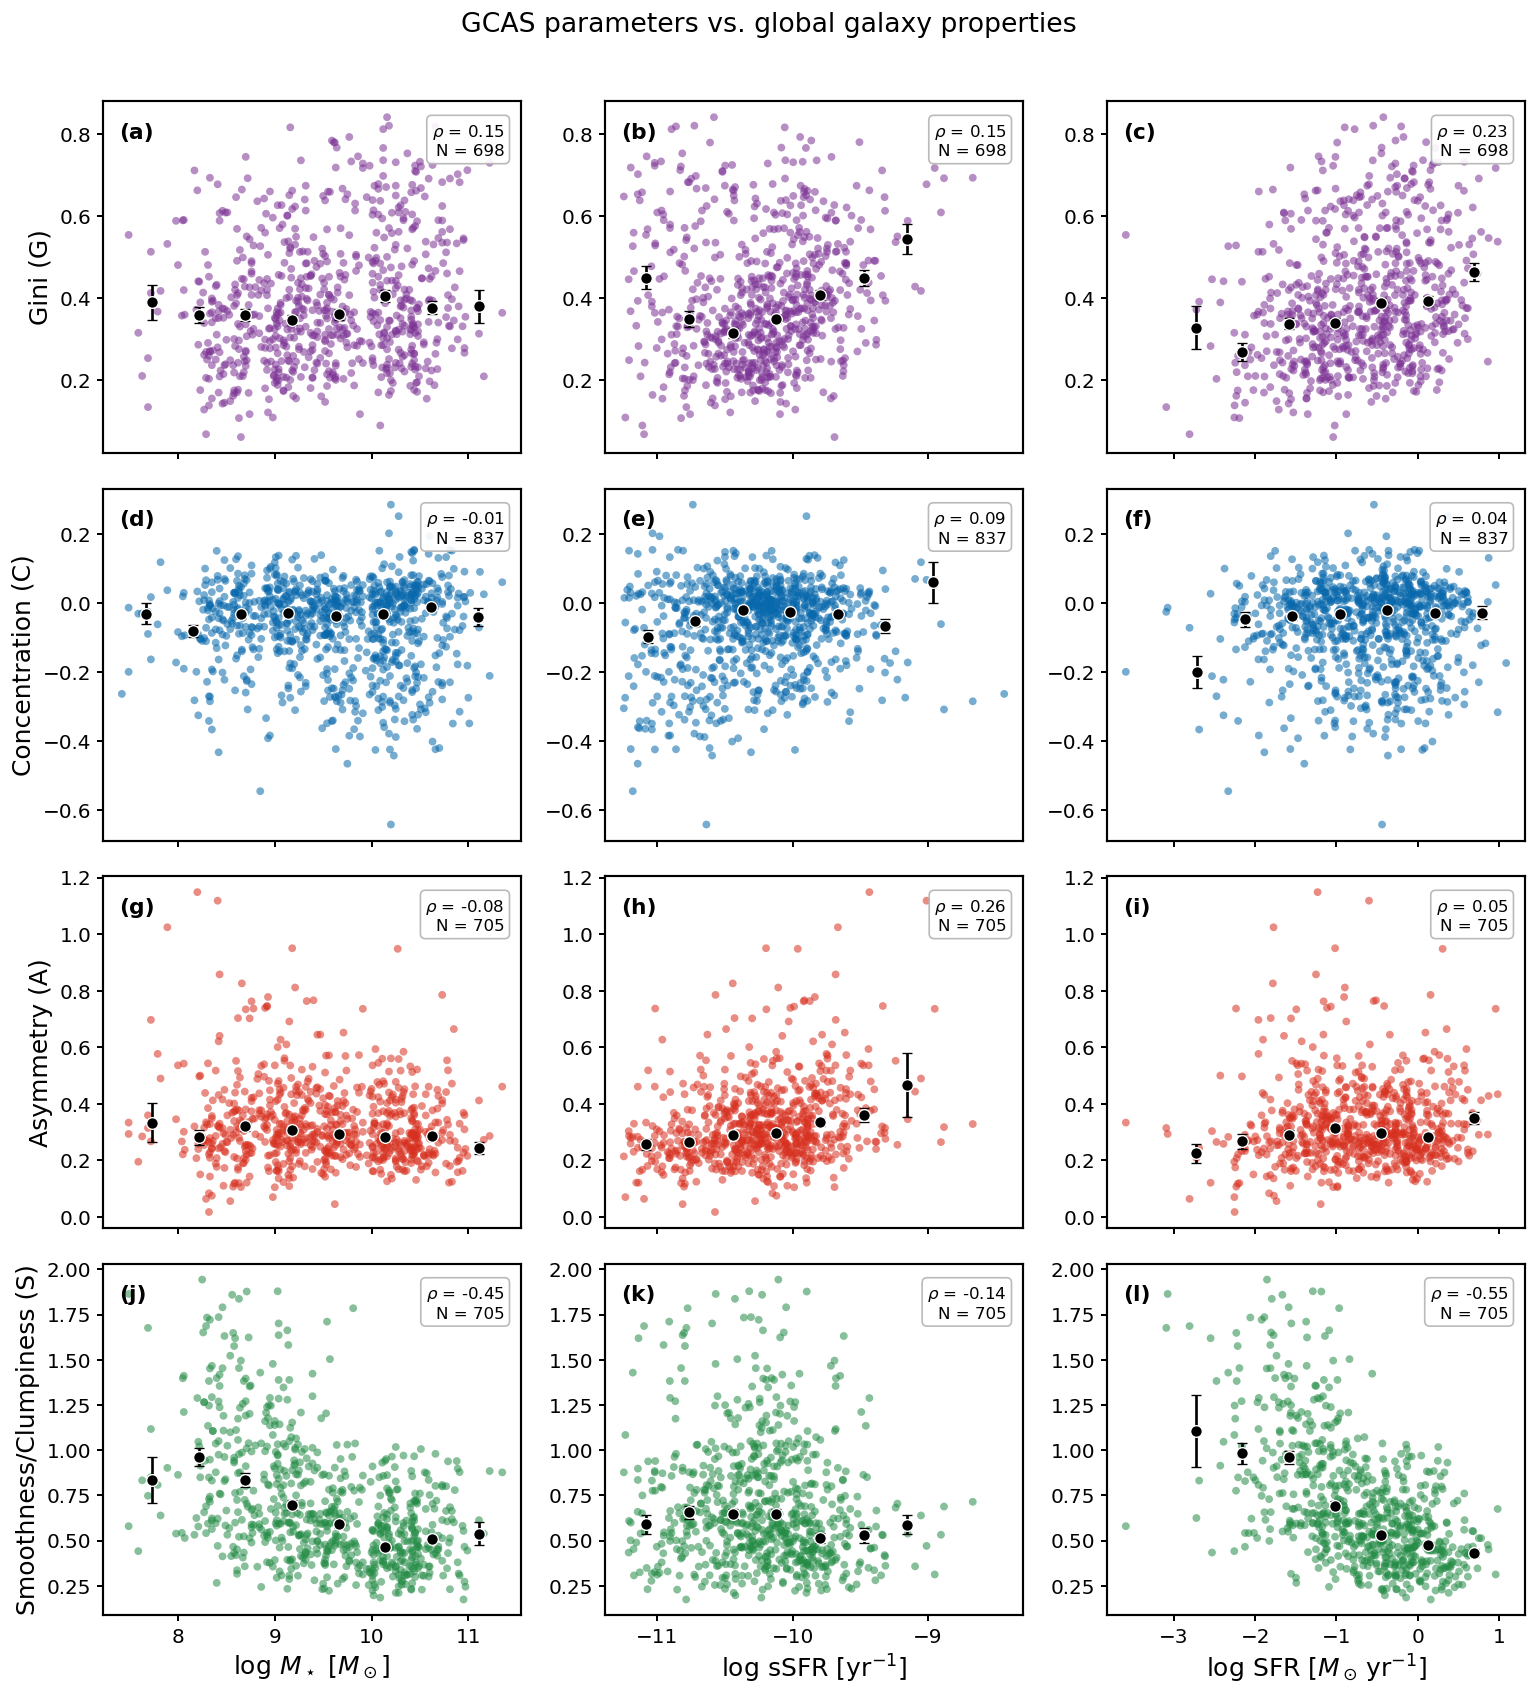

In [2]:


import string
global_props = [
    ('log_Mstar', r'$\log\,M_\star \ [M_\odot]$'),
    ('log_sSFR', r'$\log\,\mathrm{sSFR} \ [\mathrm{yr}^{-1}]$'),
    ('log_SFR', r'$\log\,\mathrm{SFR} \ [M_\odot\,\mathrm{yr}^{-1}]$'),
]

fig, axes = plt.subplots(4, 3, figsize=(13, 14), sharex='col')
letters = iter(string.ascii_lowercase)

for i, metric in enumerate(GCAS):
    valid_col = f'in_{metric}'
    sub = purity[purity[valid_col] == True] if valid_col in purity.columns else purity[purity[metric].notna()]
    y = sub[metric].values
    for j, (prop, label) in enumerate(global_props):
        ax = axes[i, j]
        x = sub[prop].values
        ax.scatter(x, y, s=22, alpha=0.55, color=GCAS_COLOR[metric], edgecolor='none')
        binned_median_errorbar(ax, x, y, bins=8)
        spearman_annotate(ax, x, y)
        panel_label(ax, next(letters))
        if i == 3:
            ax.set_xlabel(label)
        if j == 0:
            ax.set_ylabel(GCAS_LABELS[metric])

plt.suptitle('GCAS parameters vs. global galaxy properties', y=1.01, fontsize=16)
plt.tight_layout()
#plt.savefig('fig2_gcas_vs_global.png', bbox_inches='tight')
plt.show()


## Figure 3 — GCAS vs. displacement from the SFMS (ΔMS)

**Question this answers:** rather than Mstar and sSFR separately (which are
correlated with each other), does each GCAS parameter track a galaxy's
evolutionary state — how far above/below the star-forming main sequence it
sits? ΔMS collapses the Mstar–sSFR plane into one physically interpretable axis
(bursting → main-sequence → quenching).

Uses the `delta_ms` column already computed in the master catalogue.

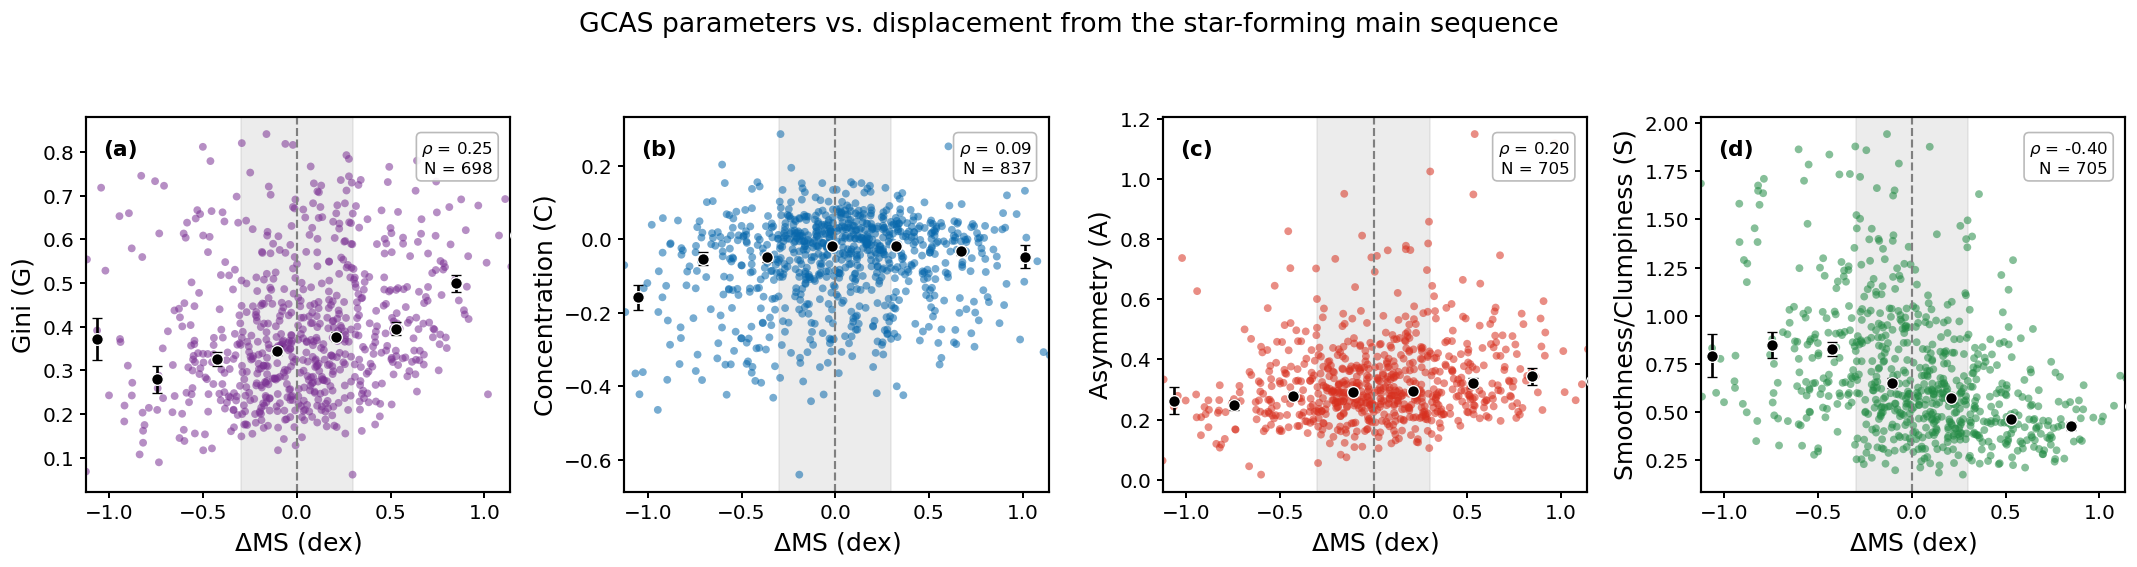

In [3]:

import string
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=False)

# shared x-range across all four panels (previously each panel used its own mask's range)
xmin = purity['delta_ms'].quantile(0.005)
xmax = purity['delta_ms'].quantile(0.995)

# reuse the same on-MS scatter band as Figure 1 (sigma computed the same way,
# restricted to the SFMS fit's valid mass range 9.0-11.0) so the two figures
# are visually and numerically consistent
fit_mass_range = (9.0, 11.0)
in_fit_range = (purity['log_Mstar'] >= fit_mass_range[0]) & (purity['log_Mstar'] <= fit_mass_range[1])
sigma_ms = 0.3

letters = iter(string.ascii_lowercase)
for ax, metric in zip(axes, GCAS):
    valid_col = f'in_{metric}'
    sub = purity[purity[valid_col] == True] if valid_col in purity.columns else purity[purity[metric].notna()]
    x = sub['delta_ms'].values
    y = sub[metric].values
    ax.axvspan(-sigma_ms, sigma_ms, color='0.6', alpha=0.18, zorder=0)
    ax.scatter(x, y, s=22, alpha=0.55, color=GCAS_COLOR[metric], edgecolor='none')
    binned_median_errorbar(ax, x, y, bins=8)
    ax.axvline(0, color='0.5', ls='--', lw=1.3)
    ax.set_xlim(xmin, xmax)
    # label the band in-place (bottom of panel) rather than via legend, to avoid
    # colliding with the panel letter (top-left) and Spearman annotation (top-right)
    #ax.text(0, 0.03, f'on-MS ($\\pm${sigma_ms:.2f} dex)', transform=ax.get_xaxis_transform(),
            #ha='center', va='bottom', fontsize=8.5, color='0.35')
    spearman_annotate(ax, x, y)
    panel_label(ax, next(letters))
    ax.set_xlabel(r'$\Delta\mathrm{MS}$ (dex)')
    ax.set_ylabel(GCAS_LABELS[metric])

plt.suptitle('GCAS parameters vs. displacement from the star-forming main sequence', y=1.05, fontsize=16)
plt.tight_layout()
#plt.savefig('fig3_gcas_vs_deltaMS.png', bbox_inches='tight')
plt.show()



## Figure 4 — GCAS vs. environment (categorical, mass-controlled)

**Question this answers:** does local environment (isolated / satellite /
central) shift the distribution of each GCAS parameter, once stellar mass is
controlled for? Following Wang (2022, Fig. 8), this restricts to a single
stellar-mass slice before comparing environment categories via histogram,
rather than letting Mstar vary freely (which would confound the comparison).

**Slice used:** `8.5 < log(M*/Msun) <= 10.5`, GAMA-only subsample
(`environment == 'GAMA'`), split by `group_status`
(isolated N=281, satellite N=140, central N=121 in this slice — well-populated
in all three categories). A second, lower-mass slice (7.5–9.5, mirroring
Wang's exact range) is included for comparison.

Mstar slice 9.5-10.5: N=275, isolated=124, satellite=72, central=79


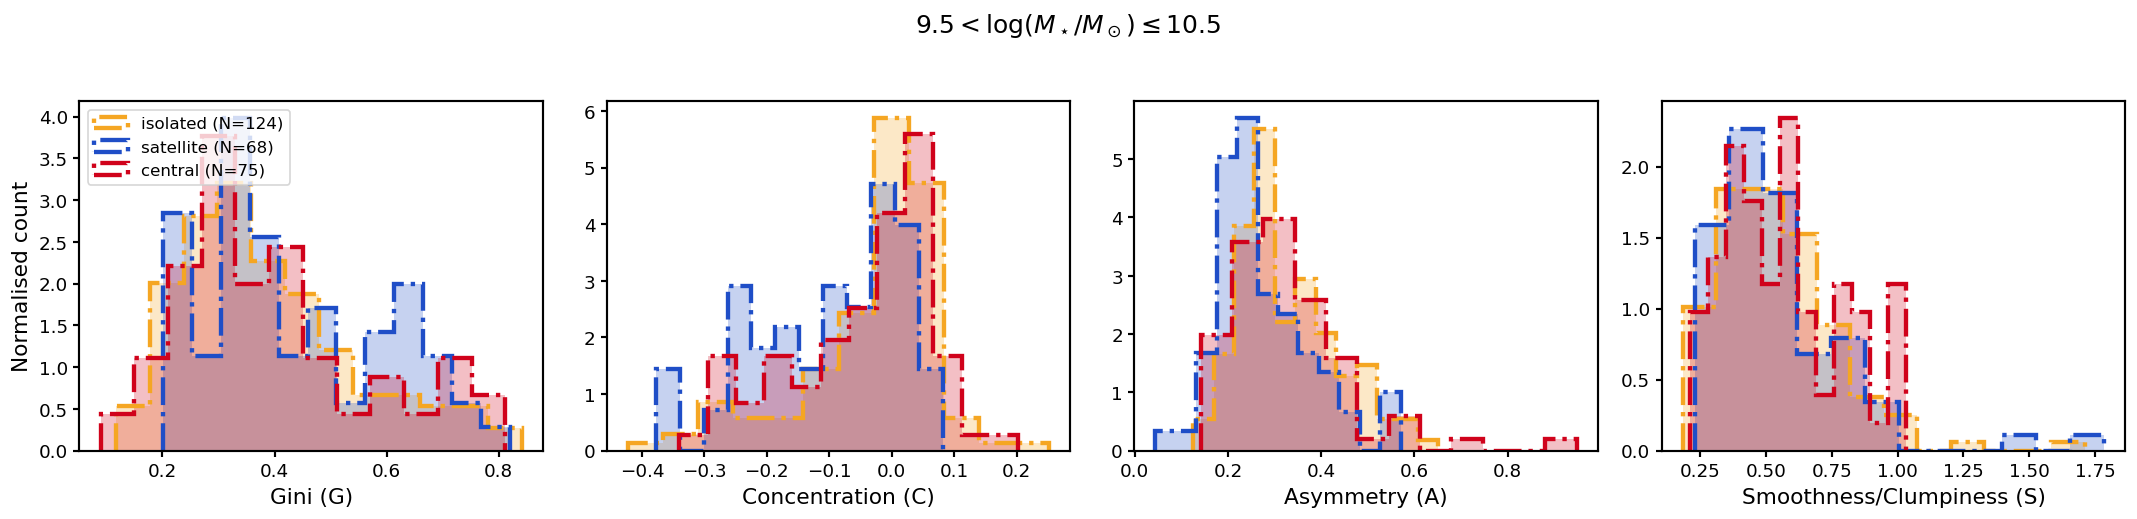

Mstar slice 8.5-9.5: N=267, isolated=157, satellite=68, central=42


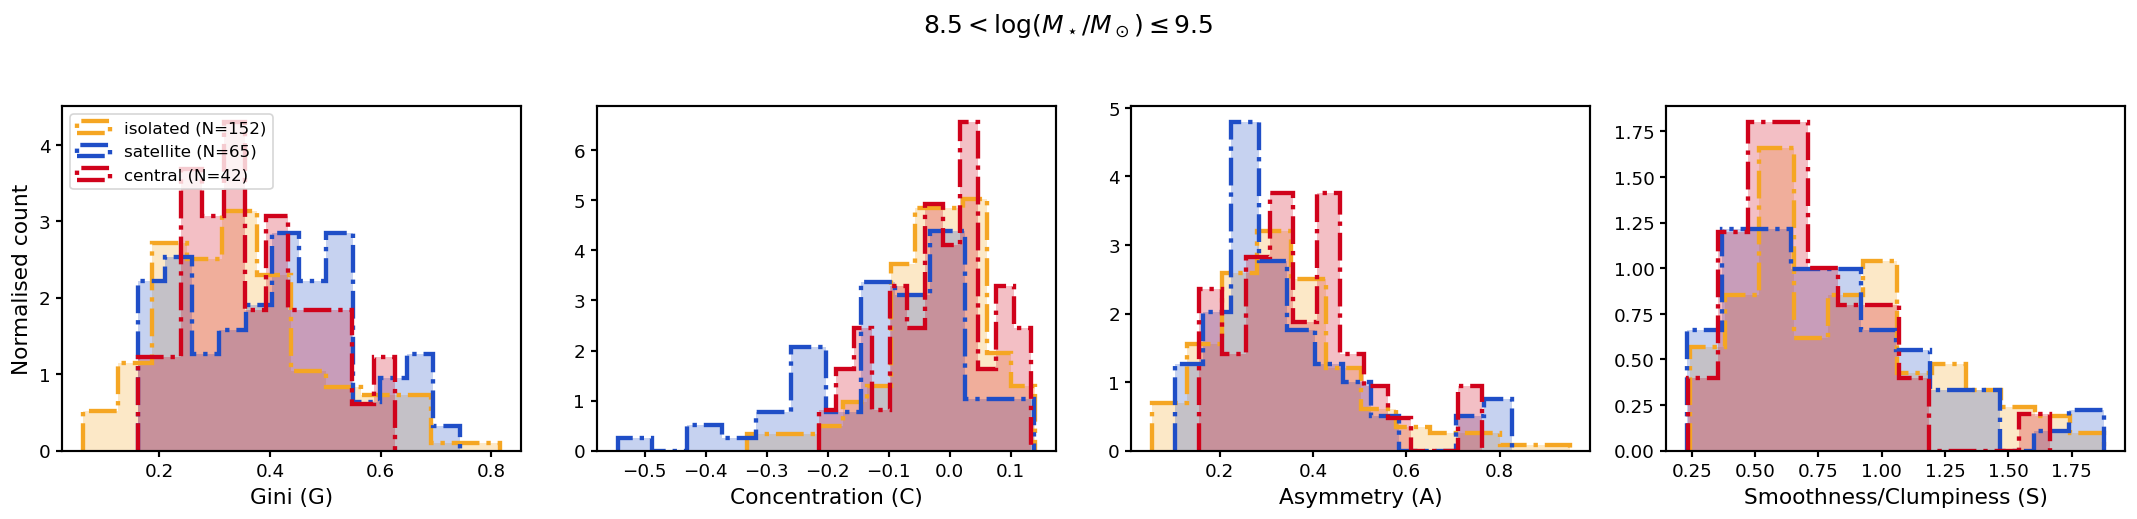

In [4]:
mass_slices = [(9.5, 10.5), (8.5, 9.5)]
gama_only = purity[purity['environment'] == 'GAMA'].copy()

status_order = ['isolated', 'satellite', 'central']
status_color = {'isolated': '#F5A623', 'satellite': '#1F4EC7', 'central': '#D0021B'}
status_ls = {'isolated': '-.', 'satellite': '-.', 'central': '-.'}

for lo, hi in mass_slices:
    sl = gama_only[(gama_only['log_Mstar'] > lo) & (gama_only['log_Mstar'] <= hi)]
    counts = sl['group_status'].value_counts()
    print(f'Mstar slice {lo}-{hi}: N={len(sl)}, ' +
          ', '.join(f'{k}={counts.get(k,0)}' for k in status_order))

    fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
    for ax, metric in zip(axes, GCAS):
        valid_col = f'in_{metric}'
        m = sl[sl[valid_col] == True] if valid_col in sl.columns else sl[sl[metric].notna()]
        for status in status_order:
            vals = m.loc[m['group_status'] == status, metric].dropna()
            if len(vals) < 5:
                continue
            ax.hist(vals, bins=12, histtype='stepfilled', facecolor=status_color[status],
                alpha=0.25, density=True, zorder=1)
            ax.hist(vals, bins=12, histtype='step', edgecolor=status_color[status],
                lw=2.6, linestyle=status_ls[status], density=True, zorder=2,
                label=f'{status} (N={len(vals)})')
        ax.set_xlabel(GCAS_LABELS[metric], fontsize=13)
        ax.tick_params(labelsize=11, width=1.3)
        for spine in ax.spines.values():
            spine.set_linewidth(1.3)

    axes[0].set_ylabel('Normalised count', fontsize=13)
    axes[0].legend(fontsize=10, loc='upper left', frameon=True)
    plt.suptitle(f'${lo} < \\log(M_\\star/M_\\odot) \\leq {hi}$', y=1.03, fontsize=15)
    plt.tight_layout()
    plt.show()

## Figure 5 — *(Deferred)*

Concentration vs. stellar mass in halo-mass bins (following Wang 2022, Fig. 7).
Deferred pending confirmation from supervisor on whether a cluster-mass proxy
exists for the SAMI cluster subsample — this determines whether the figure can
replicate Wang's full ungrouped/low-mass/high-mass/cluster structure, or
whether it is scoped to the GAMA-only subsample (N=314, no cluster panel).

## Figure 6 — Synthesis: cross-parameter correlation matrix

**Question this answers:** the closing evidence figure for the chapter. Do G,
C, A, S respond similarly to the same physical/environmental drivers, or do
they carry largely independent information? And does any single variable
(global or environmental) dominate all four? This sets up the pivot to
Chapter 4's multivariate approach — the answer here should be "no single axis
explains SF morphology," which is the whole point of doing ML on multiple
features at once.

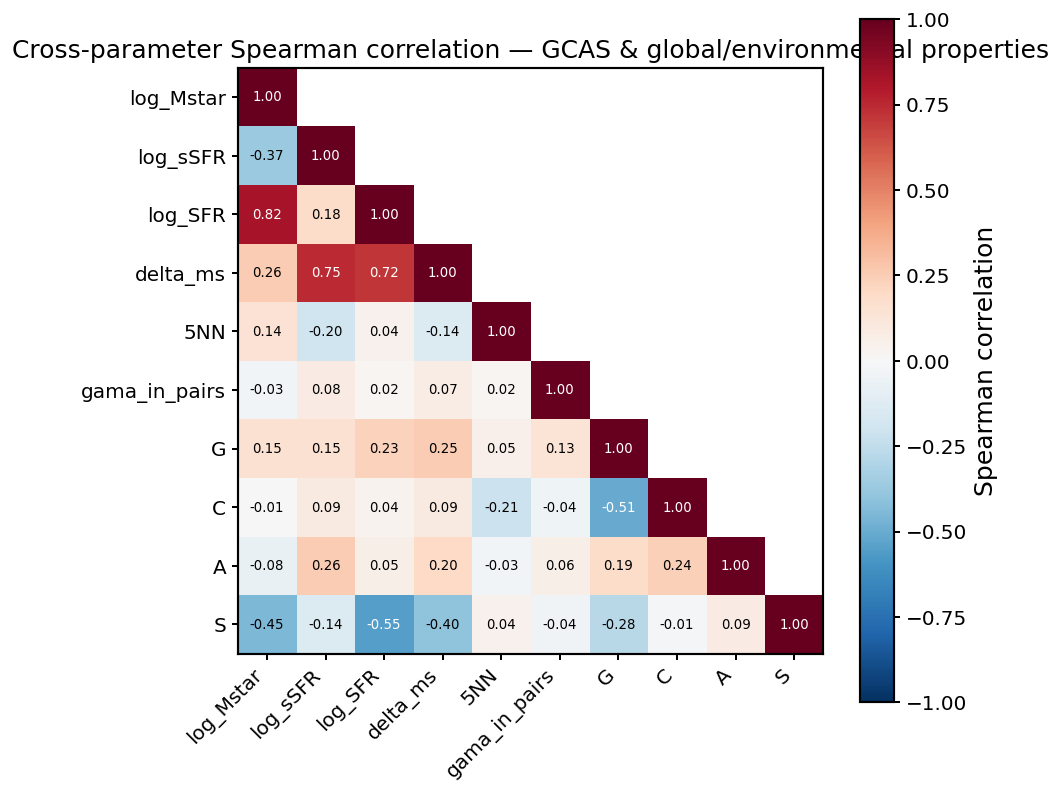

In [5]:

corr_vars = ['log_Mstar', 'log_sSFR', 'log_SFR', 'delta_ms', '5NN',
             'gama_in_pairs', 'G', 'C', 'A', 'S']

corr_df = purity[corr_vars].copy()
# cast booleans to 0/1 so they correlate sensibly
for b in ['gama_in_pairs']:
    corr_df[b] = corr_df[b].astype(float)

spearman_corr = corr_df.corr(method='spearman')

fig, ax = plt.subplots(figsize=(8, 7))
mask = np.triu(np.ones_like(spearman_corr, dtype=bool), k=1)
im = ax.imshow(np.where(mask, np.nan, spearman_corr), cmap='RdBu_r', vmin=-1, vmax=1)

ax.set_xticks(range(len(corr_vars)))
ax.set_yticks(range(len(corr_vars)))
ax.set_xticklabels(corr_vars, rotation=45, ha='right')
ax.set_yticklabels(corr_vars)

for i in range(len(corr_vars)):
    for j in range(len(corr_vars)):
        if not mask[i, j]:
            val = spearman_corr.values[i, j]
            ax.text(j, i, f'{val:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if abs(val) > 0.5 else 'black')

plt.colorbar(im, ax=ax, label='Spearman correlation')
ax.set_title('Cross-parameter Spearman correlation — GCAS & global/environmental properties')
plt.tight_layout()
#plt.savefig('fig6_synthesis_corr_matrix.png', bbox_inches='tight')
plt.show()


## Figure 7 — *(Optional, deferred)*

Case-study Hα maps for 2–3 galaxies with divergent GCAS profiles at matched
Mstar/sSFR, or at opposite ΔMS extremes. Best chosen last, once the above
figures reveal which specific galaxies make the most illustrative examples.

## Setup — config-driven scatter plots (`exploration.ipynb` style)

Ports the config-driven `plot_scatter` system from the old repo's
`src/z_plotting.py` / `src/z_samples.py` / `src/z_plot_config.py` (used
throughout `master/notebooks/exploration.ipynb`), adapted to this
pipeline's current schema (`master_sfms_2026-08-18.csv`) and kept inline
here — matching this notebook's existing style of defining helpers
(`spearman_annotate`, `panel_label`, ...) locally rather than in `src/` —
rather than as new importable modules.

**Adaptations from the old repo:**
- `SAMPLE_REGISTRY` is rebuilt against current columns. The old `"wang"`
  key (`in_wang_sf`/`in_wang_composite`) no longer applies post the
  `Full_sam` purity-cut rework (see `CHANGELOG.md`) — its closest current
  equivalent is `"full_sam"` (`in_full_sam`, the same purity cut used as
  `purity` above).
- The SFMS fit is *loaded*, not refit inline: `05_sfms.py` already wrote
  `sfms_fit_params_2026-08-18.csv` alongside `master_sfms_2026-08-18.csv`,
  and that exact fit is what produced the `delta_ms` column already in
  `df`/`purity`. Refitting here (as `exploration.ipynb` does, since its
  `master_results.csv` didn't ship fit params separately) would risk a
  fit inconsistent with `delta_ms`.

In [8]:
import sys
from pathlib import Path
from matplotlib import patheffects as pe

# Jupyter's default cwd is the notebook's own directory (sami_sf_pipeline/notebooks/)
PIPELINE_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PIPELINE_ROOT))

from src.utils.sfms import lee2015_sfms

# Load the fit written by the same 05_sfms.py run that produced
# master_sfms_2026-08-18.csv, rather than refitting inline (see markdown above)
_fit_row = pd.read_csv('../outputs/csv/sfms_fit_params_2026-09-18.csv').iloc[0]
sfms_params = (_fit_row['S0'], _fit_row['a1'], _fit_row['Mt'])
print(f"SFMS params: S0={sfms_params[0]:.3f}, a1={sfms_params[1]:.3f}, Mt={sfms_params[2]:.3f} "
      f"(n_sf_galaxies={int(_fit_row['n_sf_galaxies'])}, from {_fit_row['input_master_csv']})")

# ── Axis labels ───────────────────────────────────────────────────────────
AXIS_LABELS = {
    "log_Mstar" : r"$\log(M_\star / M_\odot)$",
    "log_SFR"   : r"$\log(\mathrm{SFR} / M_\odot\,\mathrm{yr}^{-1})$",
    "log_sSFR"  : r"$\log(\mathrm{sSFR} / \mathrm{yr}^{-1})$",
    "delta_ms"  : r"$\Delta\mathrm{MS}$",
    "galclass"  : "Environment (halo mass bin)",
    "G": "Gini", "C": "Concentration", "A": "Asymmetry", "S": "Clumpiness",
}

# ── Colour scales per metric ─────────────────────────────────────────────
CMAPS = {
    "G": "plasma", "C": "plasma", "A": "plasma", "S": "plasma",
    "delta_ms": "coolwarm",
    "log_SFR": "viridis", "log_sSFR": "viridis", "log_Mstar": "viridis",
}

# ── galclass bins (halo-mass groups, Wang+2022 — galclass is group mass,
# not an AGN flag) ────────────────────────────────────────────────────────
GALCLASS_ORDER  = [1, 2, 3, 4]
GALCLASS_LABELS = {
    1: r"Ungrouped",
    2: r"Low-mass group ($M_{200} \leq 10^{12.5}$)",
    3: r"High-mass group ($10^{12.5} < M_{200} \leq 10^{14}$)",
    4: r"Cluster ($M_{200} > 10^{14}$)",
}
GALCLASS_COLOURS = {1: "#4477AA", 2: "#66CCEE", 3: "#CCBB44", 4: "#EE6677"}

# ── Highlight markers (up to 4 CATIDs per plot) ──────────────────────────
HIGHLIGHT_STYLES = [{"marker": "o"}, {"marker": "s"}, {"marker": "^"}, {"marker": "D"}]

VALID_X = {"log_Mstar", "galclass"}
VALID_Y = {"log_SFR", "log_sSFR", "log_Mstar", "delta_ms", "galclass"}
VALID_C = {"G", "C", "A", "S", "delta_ms", "log_SFR", "log_sSFR", "log_Mstar", "galclass"}

# ── Sample registry, adapted to master_sfms_2026-08-18.csv's columns ─────
# (old repo's "wang" key -> "full_sam"/in_full_sam; in_wang_sf/in_wang_composite
# no longer exist post the Full_sam purity-cut rework — see CHANGELOG.md)
def _all_galaxies(d):       return pd.Series(True, index=d.index)
def _full_sam(d):           return d["in_full_sam"] == True
def _pure_sf(d):            return d["spectral_class"] == "pure_SF"
def _composite_sf(d):       return d["spectral_class"] == "composite_SF"
def _has_sfr(d):            return d["SFR"].notna()
def _close_pairs_100kpc(d): return d["gama_close_pair_100kpc"] == True
def _close_pairs_50kpc(d):  return d["gama_close_pair_50kpc"] == True
def _gama_region(d):        return d["environment"] == "GAMA"
def _cluster_region(d):     return d["environment"] == "Cluster"
def _sfr_cut(d, min_log_sfr=-2.0): return d["log_SFR"] > min_log_sfr

SAMPLE_REGISTRY = {
    "all"             : _all_galaxies,
    "full_sam"        : _full_sam,
    "pure_sf"         : _pure_sf,
    "composite_sf"    : _composite_sf,
    "has_sfr"         : _has_sfr,
    "close_pairs_100" : _close_pairs_100kpc,
    "close_pairs_50"  : _close_pairs_50kpc,
    "gama"            : _gama_region,
    "cluster"         : _cluster_region,
}

def get_sample(d, sample_key, min_log_sfr=None):
    """Apply a named SAMPLE_REGISTRY filter to d, optionally AND'd with an SFR floor."""
    if sample_key not in SAMPLE_REGISTRY:
        raise ValueError(f"Unknown sample '{sample_key}'. Valid options: {list(SAMPLE_REGISTRY)}")
    mask = SAMPLE_REGISTRY[sample_key](d)
    if min_log_sfr is not None:
        mask = mask & _sfr_cut(d, min_log_sfr)
    return d[mask].copy()

def draw_highlights(ax, df_plot, x_col, y_col, catids):
    """Circle up to 4 galaxies by CATID on an existing axes, each with a distinct marker + label."""
    if not catids:
        return
    legend_elements = []
    for i, catid in enumerate(catids[:4]):
        style = HIGHLIGHT_STYLES[i]
        row = df_plot[df_plot["CATID"].astype(str) == str(catid)]
        if row.empty:
            print(f"  [highlight] CATID {catid} not found in current sample")
            continue
        xval, yval = row[x_col].values[0], row[y_col].values[0]
        ax.scatter(xval, yval, marker=style["marker"], s=120, facecolors="none",
                   edgecolors="black", linewidths=1.8, zorder=10)
        ax.annotate(str(catid), xy=(xval, yval), xytext=(6, 6), textcoords="offset points",
                    fontsize=7, fontweight="bold", color="black", zorder=11)
        legend_elements.append(plt.scatter([], [], marker=style["marker"], s=60,
                    facecolors="none", edgecolors="black", linewidths=1.5, label=str(catid)))
    if legend_elements:
        ax.legend(handles=legend_elements, title="Highlighted CATID",
                  fontsize=7, title_fontsize=7, loc="upper left")

def _validate_config(config):
    x, y, c = config.get("x"), config.get("y"), config.get("colour_by")
    if x not in VALID_X:
        raise ValueError(f"x='{x}' not valid. Choose from {VALID_X}")
    if y not in VALID_Y:
        raise ValueError(f"y='{y}' not valid. Choose from {VALID_Y}")
    if c not in VALID_C:
        raise ValueError(f"colour_by='{c}' not valid. Choose from {VALID_C}")

def plot_scatter(d, sfms_params, config, ax=None):
    """
    Core scatter plot function driven entirely by config dict.

    Config keys
    -----------
    x, y, colour_by   : str    column names (see VALID_X / VALID_Y / VALID_C)
    sample            : str    key from SAMPLE_REGISTRY (default "all")
    sfr_cut           : float  minimum log(SFR) filter (default None)
    show_sfms         : bool   overlay SFMS line (default True)
    show_sfms_bands   : bool   overlay +/-0.3 dex bands (default False)
    show_median_bins  : bool   overlay median per mass bin (default False)
    median_sfr_floor  : float  SFR floor for median bins (default -1.0)
    title             : str    optional plot title
    highlight         : list   up to 4 CATIDs to circle/label
    vmin / vmax       : float  optional colour scale limits
    cmap              : str    optional colourmap override (default: CMAPS[colour_by])
    """
    _validate_config(config)
    x_col, y_col, colour_col = config["x"], config["y"], config["colour_by"]
    sample_key = config.get("sample", "all")
    min_sfr    = config.get("sfr_cut", None)
    show_sfms  = config.get("show_sfms", True)
    show_bands = config.get("show_sfms_bands", False)
    show_meds  = config.get("show_median_bins", False)
    title      = config.get("title", "")

    df_plot = get_sample(d, sample_key, min_log_sfr=min_sfr)

    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 5))
    else:
        fig = ax.get_figure()

    # ── Scatter: continuous colour scale ─────────────────────────────────
    if colour_col != "galclass":
        vmin = config.get("vmin", np.nanpercentile(df_plot[colour_col], 5))
        vmax = config.get("vmax", np.nanpercentile(df_plot[colour_col], 95))
        cmap = config.get("cmap", CMAPS.get(colour_col, "viridis"))
        sc = ax.scatter(df_plot[x_col], df_plot[y_col], c=df_plot[colour_col],
                        cmap=cmap, vmin=vmin, vmax=vmax, s=22, alpha=0.55, linewidths=0)
        cbar = fig.colorbar(sc, ax=ax, pad=0.02)
        cbar.set_label(AXIS_LABELS.get(colour_col, colour_col), fontsize=13)
        cbar.ax.tick_params(labelsize=11)
        
    # ── Scatter: discrete galclass colour ────────────────────────────────
    else:
        df_plot = df_plot.copy()
        df_plot["galclass"] = pd.to_numeric(df_plot["galclass"], errors="coerce").astype("Int64")
        for gc in GALCLASS_ORDER:
            mask = df_plot["galclass"] == gc
            if mask.sum() == 0:
                continue
            ax.scatter(df_plot.loc[mask, x_col], df_plot.loc[mask, y_col],
                      color=GALCLASS_COLOURS[gc], label=GALCLASS_LABELS[gc],
                      s=12, alpha=0.75, linewidths=0)
        ax.legend(fontsize=10, loc="upper left", title="Environment", title_fontsize=10)

    # ── SFMS line: log_SFR vs log_Mstar ───────────────────────────────────
    if show_sfms and x_col == "log_Mstar" and y_col == "log_SFR":
        mass_range = np.linspace(df_plot[x_col].min() - 0.1, df_plot[x_col].max() + 0.1, 300)
        sfms_line = lee2015_sfms(mass_range, *sfms_params)
        ax.plot(mass_range, sfms_line, color="black", lw=2.2, ls="-", label="SFMS (Lee+2015 fit)", zorder=5, 
                path_effects=[pe.Stroke(linewidth=3.6, foreground="white"), pe.Normal()])
        if show_bands:
            ax.fill_between(mass_range, sfms_line - 0.3, sfms_line + 0.3,
                            color="gold", alpha=0.15, zorder=4)

    # ── SFMS line: log_sSFR vs log_Mstar ──────────────────────────────────
    if show_sfms and x_col == "log_Mstar" and y_col == "log_sSFR":
        mass_range = np.linspace(df_plot[x_col].min() - 0.1, df_plot[x_col].max() + 0.1, 300)
        sfms_ssfr = lee2015_sfms(mass_range, *sfms_params) - mass_range
        ax.plot(mass_range, sfms_ssfr, color="black", lw=2.2, ls="-", label="SFMS", zorder=5, 
                path_effects=[pe.Stroke(linewidth=3.6, foreground="white"), pe.Normal()])

    # ── Median bin overlay ─────────────────────────────────────────────────
    if show_meds and x_col == "log_Mstar" and y_col == "log_SFR":
        sfr_floor = config.get("median_sfr_floor", -1.0)
        bins = np.arange(8.0, 11.8, 0.2)
        bin_mids = bins[:-1] + 0.1
        medians, valid_mid = [], []
        for i in range(len(bins) - 1):
            mask = ((df_plot[x_col] >= bins[i]) & (df_plot[x_col] < bins[i + 1]) &
                    np.isfinite(df_plot[y_col]) & (df_plot[y_col] >= sfr_floor))
            if mask.sum() >= 5:
                medians.append(np.median(df_plot.loc[mask, y_col]))
                valid_mid.append(bin_mids[i])
        ax.plot(valid_mid, medians, color="#2d8a4e", lw=1.5, ls="--", marker="o",
                markersize=4, label="Median per bin", zorder=6)

    # ── Legend for SFMS/median overlays ────────────────────────────────────
    if x_col == "log_Mstar" and y_col in ("log_SFR", "log_sSFR"):
        ax.legend(fontsize=10, loc="upper right")

    # ── Highlights ──────────────────────────────────────────────────────────
    highlight_ids = config.get("highlight", [])
    if highlight_ids and x_col == "log_Mstar" and y_col in ("log_SFR", "log_sSFR"):
        draw_highlights(ax, df_plot, x_col, y_col, highlight_ids)

    ax.set_xlabel(AXIS_LABELS.get(x_col, x_col), fontsize=15)
    ax.set_ylabel(AXIS_LABELS.get(y_col, y_col), fontsize=15)
    ax.tick_params(labelsize=12, width=1.2)
    for spine in ax.spines.values():
        spine.set_linewidth(1.3)
    if title:
        ax.set_title(title, fontsize=14)

    fig.tight_layout()
    return fig, ax

SFMS params: S0=2.871, a1=0.218, Mt=9.889 (n_sf_galaxies=1657, from master_2026-09-18.csv)


## Demo — config-driven scatter

Same shape as the `exploration.ipynb` "Wang Full Sample" cells, updated to
the `"full_sam"` sample key and using `HIGHLIGHT_CATIDS` from
`sfms_explorer.ipynb`. Edit `config` and re-run to try other GCAS
parameters (`"C"`, `"A"`, `"S"`), `"galclass"`, `y="log_sSFR"`, or other
`SAMPLE_REGISTRY` keys (`"pure_sf"`, `"composite_sf"`, `"gama"`,
`"cluster"`, `"close_pairs_100"`, `"close_pairs_50"`).

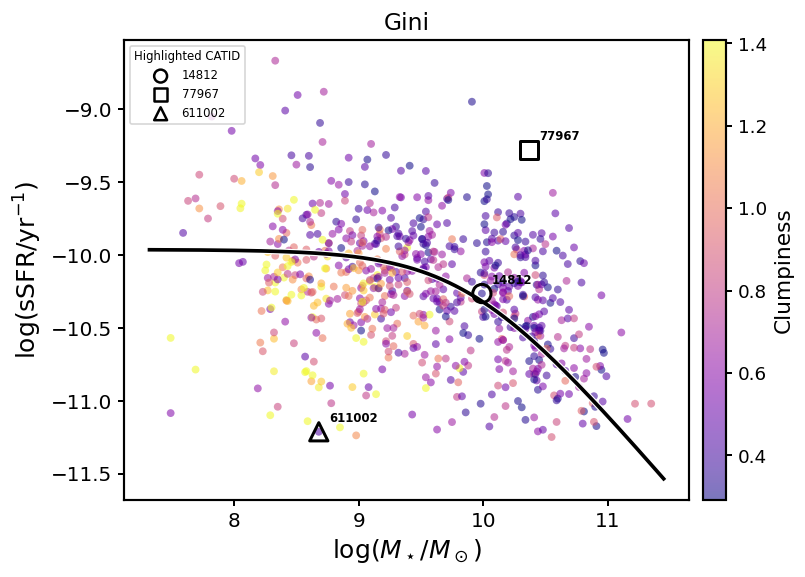

In [9]:
config = {
    "x"               : "log_Mstar",
    "y"               : "log_sSFR",
    "colour_by"       : "S",
    "sample"          : "full_sam",
    "sfr_cut"         : None,
    "show_sfms"       : True,
    "show_sfms_bands" : True,
    "show_median_bins": True,
    "title"           : "Gini",
    "highlight"       : [14812, 77967, 611002],
}
fig, ax = plot_scatter(df, sfms_params, config)
plt.show()

## Demo — 2×2 grid, one panel per GCAS metric

log_sSFR vs log_Mstar for `full_sam`, coloured by G/C/A/S in turn — one
`plot_scatter` call per panel via its `ax=` argument, sharing the same
sample/SFMS overlay settings across all four.

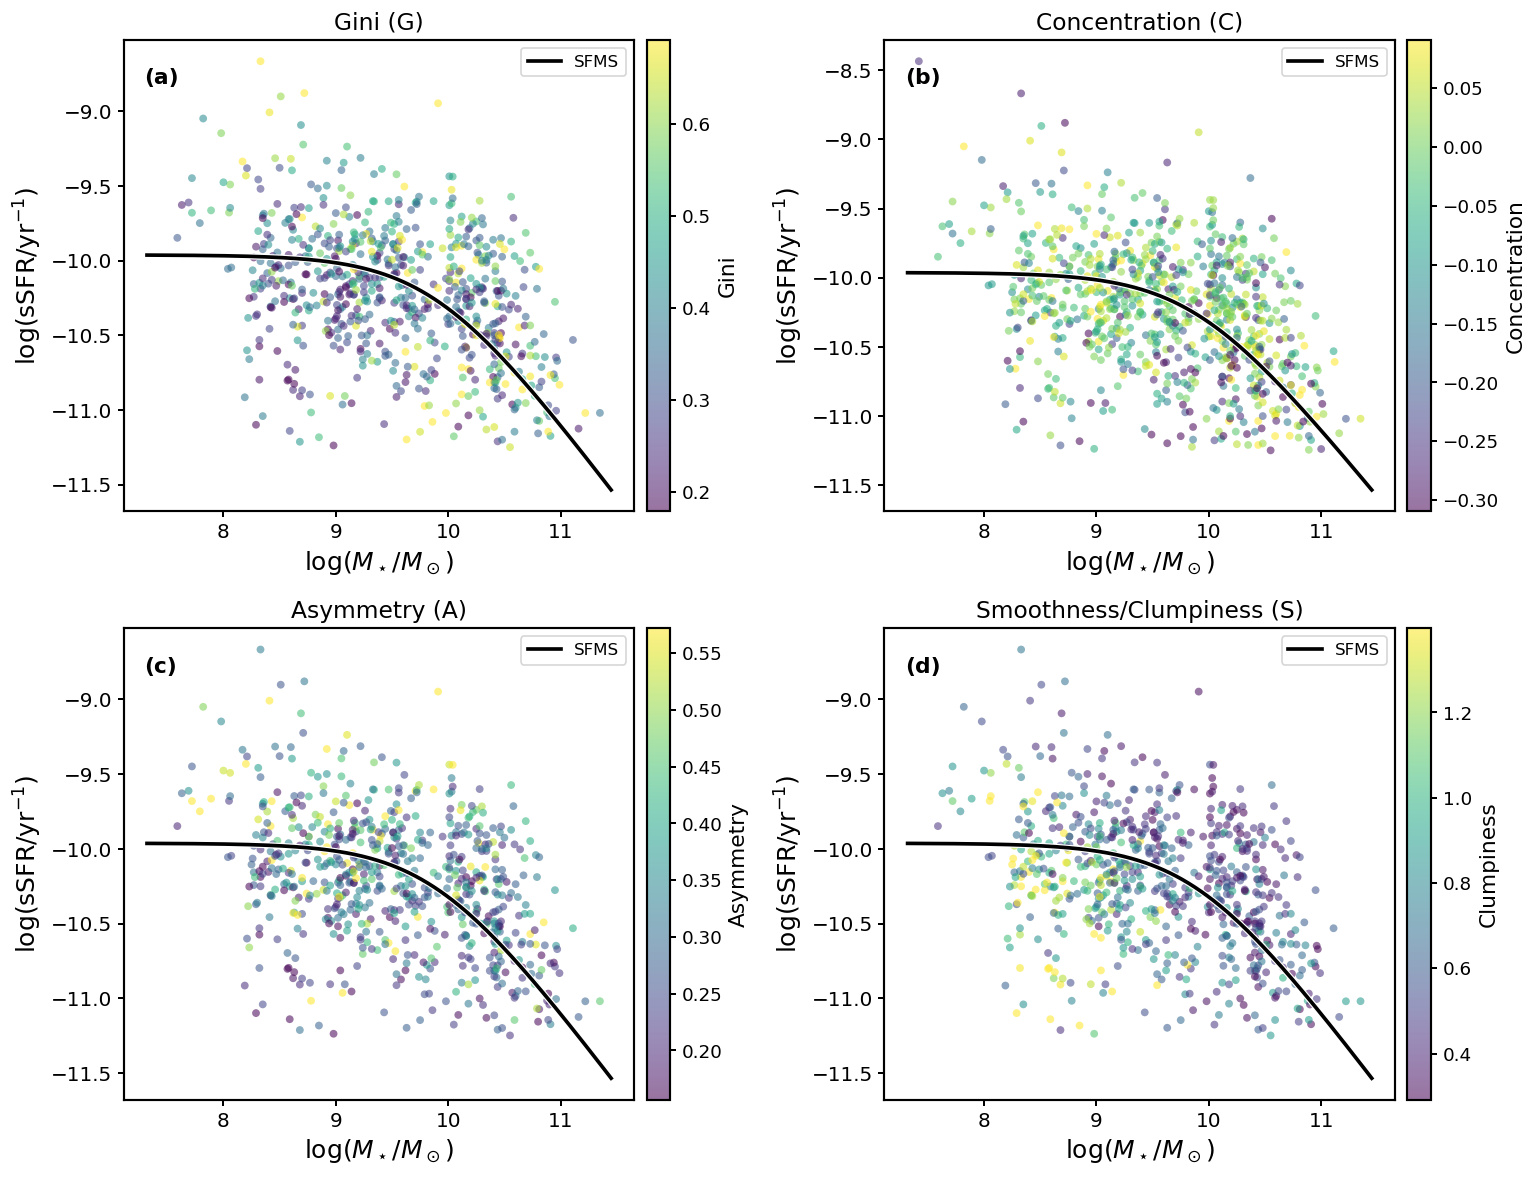

: 

In [ ]:
import string

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
letters = iter(string.ascii_lowercase)

for metric, ax in zip(GCAS, axes.flat):
    config = {
        "x"               : "log_Mstar",
        "y"               : "log_sSFR",
        "colour_by"       : metric,
        "sample"          : "full_sam",
        "sfr_cut"         : -3,
        "show_sfms"       : True,
        "show_sfms_bands" : True,
        "show_median_bins": True,
        "cmap"            : "viridis",
        "title"           : f"{GCAS_LABELS[metric]}",
    }
    plot_scatter(df, sfms_params, config, ax=ax)
    panel_label(ax, next(letters))

plt.tight_layout()
plt.show()